# Разведочный анализ данных

Импорты


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

**загрузка данных**

In [3]:
matches = pd.read_parquet('data/matches.parquet')
items_human = pd.read_parquet('data/items_human.parquet')


**info**

In [4]:
print(matches.info())
print(matches.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365654 entries, 0 to 365653
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id1     365654 non-null  int64  
 1   id2     365654 non-null  int64  
 2   target  365654 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 8.4 MB
None
   id1           id2  target
0   32  188978721454     0.0
1   34  197568543106     0.0
2   37  661425040668     0.0
3   97  274877917548     0.0
4  154  283467899529     0.0


In [5]:
print(items_human.info())
print(items_human.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 711304 entries, 0 to 711303
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id          711304 non-null  int64 
 1   name        711304 non-null  object
 2   attributes  711304 non-null  object
 3   category    711304 non-null  object
dtypes: int64(1), object(3)
memory usage: 21.7+ MB
None
     id                                               name  \
0   197  victor reinz прокладка впускного коллектора ар...   
1   415             stellox диск тормозной, арт. 8500892sx   
2   427        комплект подшипника ступицы колеса lynxauto   
3  1027      kraft подшипник ступицы, арт. kt204632, 1 шт.   
4  2639                    фильтр салонный skoda fabia 00-   

                                          attributes    category  
0  {"артикул":"703315700","бренд":"victor reinz",...  Автотовары  
1  {"артикул":"stellox_8500892sx","место установк...  Автотовары  
2  {"артикул п

**разный товар (target = 0)**

In [6]:
pd.set_option('display.max_colwidth', None)

id1_0 = matches.loc[0, 'id1']
id2_0 = matches.loc[0, 'id2']


row1_0 = items_human[items_human['id'] == id1_0]
row2_0 = items_human[items_human['id'] == id2_0]

print(row1_0['name'])
print(row2_0['name'])

print(row1_0['attributes'])
print(row2_0['attributes'])


37752    очки с футляром-змейка fedrov мод. 1047 цвет 3 с линзами romeo 1.56 hmc/emi -2.00 рц 62-64
Name: name, dtype: object
45853    фотохромные очки с футляром-змейка fedrov мод. 1047 цвет 3 с линзами romeo 1.56 fast photocolor brown, hmc+ -3.00 рц 64-66
Name: name, dtype: object
37752    {"диоптрии":"- 2.00","цвет оправы":"золотистый, коричневый","назначение":"корректирующие","конструкция":"ободковая","материал оправы":"комбинированный","материал линз":"пластик","форма оправы":"бабочка","покрытие линз":"упрочняющее, водоотталкивающее и антистатическое, металлизированное (защита от электромагнитных волн) uv-380, просветляющее","пол":"женские","ширина линзы":"56 мм","высота линзы":"52 мм","межцентровое расстояние":"62-64","длина заушника":"144 мм"}
Name: attributes, dtype: object
45853    {"наличие флексов":"да","затемнение":"коричневый фотохром 80%","бренд":"fedrov","цвет товара":"золотой","название цвета":"brown & gold","страна-изготовитель":"россия","размер заушника, мм":"144","ко

**одинаковый товар (target = 1)**

In [7]:
id1_1 = matches.loc[8, 'id1']
id2_1 = matches.loc[8, 'id2']

row1_1 = items_human[items_human['id'] == id1_1]
row2_1 = items_human[items_human['id'] == id2_1]
print(row1_1['name'])
print(row2_1['name'])
print(row1_1['attributes'])
print(row2_1['attributes'])

73372    микроволновая печь соло lg ms-20r42d
Name: name, dtype: object
107644    lg / микроволновая печь ms20r42d, 20 литров
Name: name, dtype: object
73372    {"бренд":"lg","цвет товара":"белый","программы приготовления":"разморозка","страна-изготовитель":"китай","глубина, см":"31.2","диаметр поворотного стола, см":"24.5","размеры, мм":"455 x 284 x 312","особенности микроволновой печи":"быстрый старт","высота, см":"28.4","внутреннее покрытие микроволновой печи":"эмалевое","расположение":"отдельностоящая","управление":"сенсорное","макс. мощность свч, вт":"700","вес, кг":"11.5","режимы работы микроволновой печи":"соло","технология свч":"с поворотным столом","партномер":"ms20r42d","направление открывания дверцы":"навесная с открытием налево","системы защиты":"блокировка от детей","тип":"микроволновая печь","открывание дверцы микроволновой печи":"кнопка","объем, л":"20","гарантийный срок":"12","ширина, см":"45.5"}
Name: attributes, dtype: object
107644    {"цвет":"белый","объем микроволн

**таблица items_human**


In [8]:
print(items_human['attributes'].values)

['{"артикул":"703315700","бренд":"victor reinz","партномер (артикул производителя)":"703315700","тип":"прокладка двигателя","вид техники":"легковые автомобили"}'
 '{"артикул":"stellox_8500892sx","место установки":"передние","толщина тормозного диска, мм":"28","бренд":"stellox","oem-номер":"3050086; a9064210012; 2e0615301; 68006716aa; 9064210012; 9064210212; 9064210012s; 9064210112","партномер (артикул производителя)":"8500892sx","тип":"диск тормозной","тип тормозного диска":"вентилируемый","вид техники":"легковые автомобили"}'
 '{"артикул производителя":"","бренд":"lynxauto","примечание":"внешний вид изделия может отличаться от фотографий","цена за":"1 шт.","код товара":"600000256748"}'
 ...
 '{"модель":"8634yg","артикул производителя":"8634yg200","бренд":"lazurit-online","тип":"кольцо","вид":"классическое","пол":"женский","материал изделия":"серебро","проба":"925","вставка":"хромдиопсид","количество карат":"0,75","размер":"20","средний вес изделия, г":"1,47","цвет материала":"золотист

## категории

category
Музыкальные инструменты    31923
Бытовая химия              33284
Красота и гигиена          34299
Канцелярские товары        34436
Электроника                34455
Ювелирные изделия          34759
Детские товары             34791
Бытовая техника            34887
Дом и сад                  34923
Хобби и творчество         35023
Спорт и отдых              35084
Галантерея и аксессуары    35434
Мебель                     35505
Продукты питания           35564
Аптека                     35620
Товары для животных        35663
Обувь                      35936
Строительство и ремонт     36088
Автотовары                 37752
Одежда                     45878
Name: count, dtype: int64


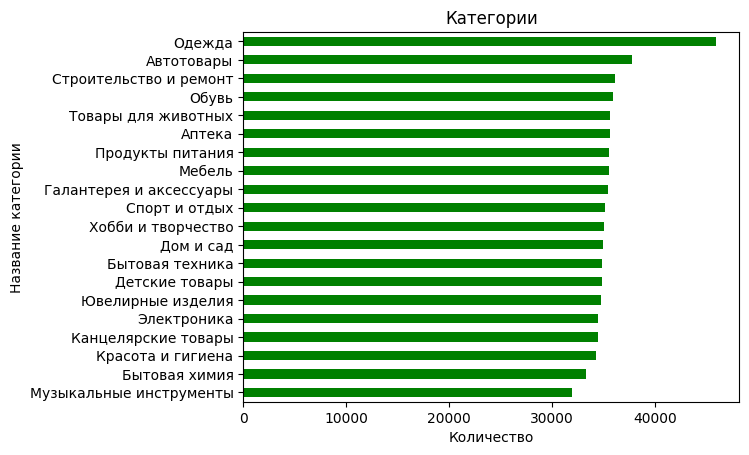

In [9]:
category = items_human['category'].value_counts()
category = category.sort_values()
category.plot.barh(color='green')
plt.title('Категории')
plt.xlabel('Количество')
plt.ylabel('Название категории')
print(category)

20 категорий, товары распределены почти равномерно

## название

In [10]:
print((items_human['name'].str.strip() == '').sum())

0


в названии нет пропусков

**гистограмма длины названия**

54.0
1
4126
count    711304.000000
mean         57.675833
std          30.357121
min           1.000000
25%          38.000000
50%          54.000000
75%          71.000000
max        4126.000000
Name: name, dtype: float64


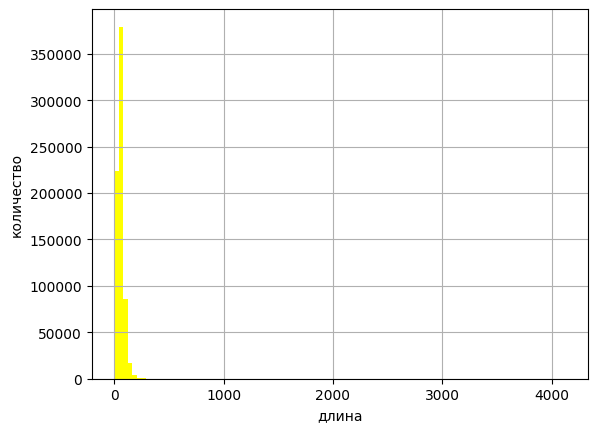

In [11]:
name_len = items_human['name'].str.len()
print(name_len.median())
print(name_len.min())
print(name_len.max())
name_len = name_len
print(name_len.describe())
plt.xlabel('длина')
plt.ylabel('количество')
name_len.hist(bins=100, color='yellow')
plt.show()



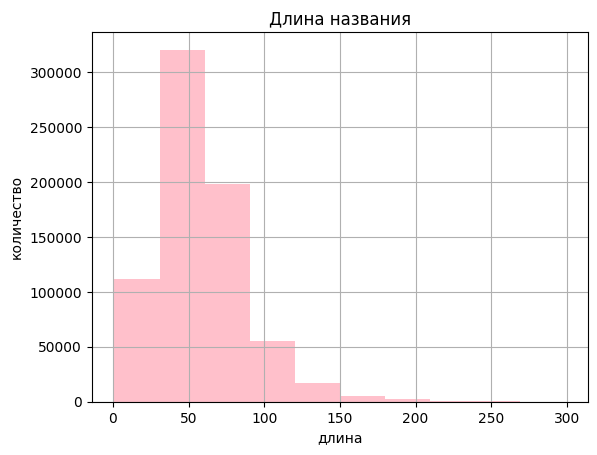

In [12]:
name_len_short = name_len[name_len < 300]
name_len_short.hist(color='pink')
plt.xlabel('длина')
plt.ylabel('количество')
plt.title('Длина названия')
plt.show()

муcорное название длины 1, но атрибутты есть

In [13]:
print(items_human[items_human['name'].str.len() == 1]['name'])
print(items_human[items_human['name'].str.len() == 2]['name'])
print(items_human[items_human['name'].str.len() == 3]['name'])

97678    /
Name: name, dtype: object
Series([], Name: name, dtype: object)
99543     фен
212571    шар
444854    топ
450600    топ
Name: name, dtype: object


In [14]:
print(items_human.loc[97678])

id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             601295460396
name                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

## характеристики

In [15]:
print((items_human['attributes'].str.strip() == '').sum())

0


attributes
16       3523
93       2166
92       2130
46       1817
81       1613
         ... 
2873        1
6665        1
11051       1
66618       1
3197        1
Name: count, Length: 3599, dtype: int64
count    711304.000000
mean        442.298653
std         608.206723
min           2.000000
25%         185.000000
50%         353.000000
75%         584.000000
max      114807.000000
Name: attributes, dtype: float64


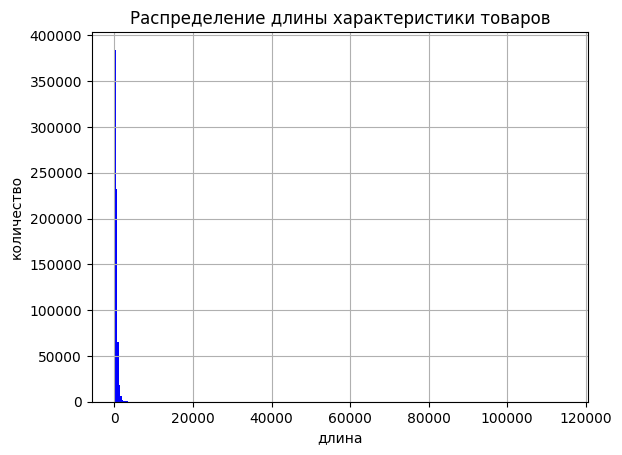

In [16]:
len_attributes = items_human['attributes'].str.len()
print(len_attributes.value_counts())
print(len_attributes.describe())
plt.title('Распределение длины характеристики товаров')
plt.xlabel('длина')
plt.ylabel('количество')
len_attributes.hist(bins=300, color='blue')
plt.show()

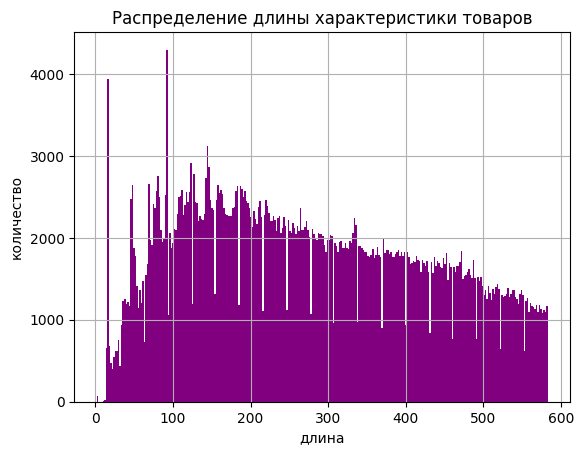

In [17]:
len_attributes_short = len_attributes[len_attributes < 584]
plt.xlabel('длина')
plt.ylabel('количество')
plt.title('Распределение длины характеристики товаров')
len_attributes_short.hist(bins=300, color='purple')
plt.show()

**у 72 товаров отсутствуют характеристики**

In [18]:
print(len(items_human[items_human['attributes'].str.len() == 2]))
print(items_human[items_human['attributes'].str.len() == 2]['attributes'])

72
1211      {}
1482      {}
3885      {}
10268     {}
25787     {}
          ..
634057    {}
641167    {}
659566    {}
676189    {}
678957    {}
Name: attributes, Length: 72, dtype: object


**откуда пики на гистограмме?**


пик 1: длина = 16


In [19]:
print(len(items_human[items_human['attributes'].str.len() == 16]))
print(items_human[items_human['attributes'].str.len() == 16])

3523
                  id  \
6213    137439091835   
9936    223338381103   
12275   283467860249   
29986   678604932729   
38669    17179926012   
...              ...   
695136  455266632225   
695737  472446461562   
698494  541165942637   
707490  755914371530   
709202  798864037078   

                                                                                name  \
6213                                                    адм / колпак ниссан гига r14   
9936             sp connect крепление на вынос руля мотоцикла sp moto stem mount pro   
12275         parkmaster / парктроник (парковочный радар) parkmaster 34u-4-a (black)   
29986                                                   адм / колпак хендай гига r15   
38669           before thawed / массажное интимное масло с ароматом кокоса - 100 мл.   
...                                                                              ...   
695136                                                пирамида продаж / серьга каффа   
69

в характеристики почти у всех {"валюта":"rub"}

пик 2: длина = 93

In [20]:
print(len(items_human[items_human['attributes'].str.len() == 93]))
print(items_human[items_human['attributes'].str.len() == 93])

2166
                  id  \
31             11456   
1837     34359832874   
1933     42949674459   
2177     42949788207   
2272     42949823576   
...              ...   
698186  532576020392   
698688  541166029968   
701930  627065272766   
706601  738734445392   
709573  807453989577   

                                                                                                           name  \
31                        patron сайлентблок подрамника задней подвески toyota mark 2/chaser/cresta gx100 96-01   
1837                                             не определен центровочные кольца из алюминия/ размер 69.1-67.1   
1933                                                                lynxauto / ремень поликлиновый lynx 6pk1470   
2177                                                     авточехлы для lada priora sd, 2014-н.в, жаккард, набор   
2272    marshall autoparts тормозные колодки задние chevrolet cruze 09-, opel astra j 09-, opel mokka 12-, opel   
...             

In [21]:
print(len(items_human[(items_human['attributes'].str.len() == 93) & (items_human['attributes'].str.contains('длина упаковки'))]))

1260


пик объясняется тем, что описания построены по одному принципу (например {"длина упаковки":"25 см","высота упаковки":"20 см","ширина упаковки":"20 см","валюта":"rub"})  с разными параметрами

## баланс классов

In [22]:
print(matches['target'].value_counts())
print(len(matches[matches['target'] == 1]) / len(matches))

target
0.0    271764
1.0     93890
Name: count, dtype: int64
0.2567727961406138


в таргете значения только 0 и 1, соотношение 1 к 3 (75% не дубли, 25 % дубли)

In [23]:
count_jpg = len(items_human[items_human['attributes'].str.contains('jpg')])
n_items = len(items_human)
print(count_jpg/n_items)
print(count_jpg)

0.02375355684770506
16896


в характеристиках есть картинки (либо карточки товаров, либо фото товара), но их всего 2.4 процента

## ВЫВОД <br>
**у товаров есть название и характеристики(набор пар «свойство: значение»);<br>
названия заполнены у всех, средняя длина 58 символов;<br>
У 72 товаров характеристики пустые; <br>
20 категорий, распределены равномерно;<br>
дублей 25,7%;<br>
картинки есть у 2,4% товаров**